In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import datasets as load_datasets

#Loading data
datasets = load_datasets.load_dataset('lukebarousse/data_jobs')
df = datasets['train'].to_pandas()

#Data cleaning
df['job_posted_date'] = pd.to_datetime(df['job_posted_date'])

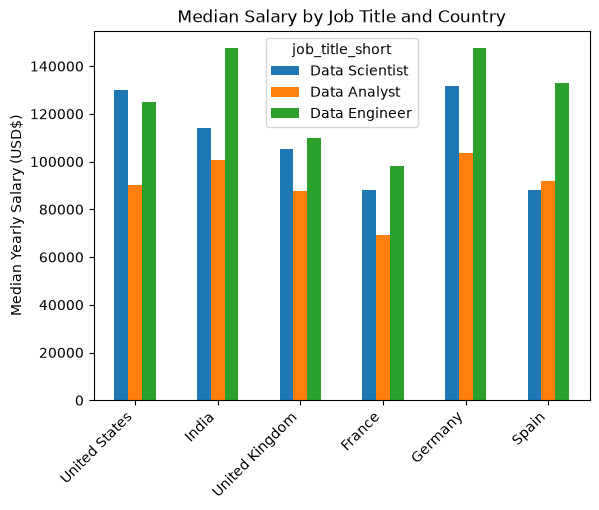

In [4]:
top_countries = df['job_country'].value_counts().head(6).index

df_job_country_salary = df.pivot_table(
    values='salary_year_avg',
    index='job_country',
    columns='job_title_short',
    aggfunc='median'
)

job_title = ['Data Scientist', 'Data Analyst', 'Data Engineer']
df_job_country_salary = df_job_country_salary.loc[top_countries]
df_job_country_salary = df_job_country_salary[job_title]

df_job_country_salary.plot(kind='bar')
plt.title('Median Salary by Job Title and Country')
plt.xlabel('')
plt.ylabel('Median Yearly Salary (USD$)')
plt.xticks(rotation=45, ha='right')
plt.show()
